In [1]:
# =============================================================================
# PART 1: IMPORTS AND DATA PREPARATION
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series
import pmdarima as pm
from pmdarima.preprocessing import FourierFeaturizer
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

In [2]:
# =============================================================================
# ML MODELS - PART 1: SETUP AND FEATURE ENGINEERING
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Time series CV
from sklearn.model_selection import TimeSeriesSplit

# Holidays
import holidays

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print("=" * 80)
print("MACHINE LEARNING MODELS: LightGBM & XGBoost")
print("=" * 80)
print("\nKey Strategy: Feature Engineering for Time Series")
print("  - Temporal features (hour, day, month)")
print("  - Lag features (past values)")
print("  - Rolling statistics (moving averages)")
print("  - Cyclical encoding (sin/cos transformations)")
print("  - Holiday indicators")
print("=" * 80)

MACHINE LEARNING MODELS: LightGBM & XGBoost

Key Strategy: Feature Engineering for Time Series
  - Temporal features (hour, day, month)
  - Lag features (past values)
  - Rolling statistics (moving averages)
  - Cyclical encoding (sin/cos transformations)
  - Holiday indicators


In [3]:
# =============================================================================
# ML MODELS - PART 2: FEATURE ENGINEERING FUNCTION
# =============================================================================

def create_time_features(df, target_col='value'):
    """
    Create comprehensive time series features from datetime index.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with datetime index and target column
    target_col : str
        Name of the target column
        
    Returns:
    --------
    DataFrame with all features
    """
    df = df.copy()
    
    # Ensure datetime index
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    
    # =========================
    # BASIC TIME FEATURES
    # =========================
    df['hour'] = df.index.hour
    df['day_of_week'] = df.index.dayofweek  # 0=Monday, 6=Sunday
    df['day_of_month'] = df.index.day
    df['day_of_year'] = df.index.dayofyear
    df['week_of_year'] = df.index.isocalendar().week
    df['month'] = df.index.month
    df['quarter'] = df.index.quarter
    df['year'] = df.index.year
    
    # =========================
    # BINARY FLAGS
    # =========================
    df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
    df['is_month_start'] = df.index.is_month_start.astype(int)
    df['is_month_end'] = df.index.is_month_end.astype(int)
    df['is_quarter_start'] = df.index.is_quarter_start.astype(int)
    df['is_quarter_end'] = df.index.is_quarter_end.astype(int)
    
    # Business hours (9am-5pm weekdays)
    df['is_business_hours'] = (
        (df['hour'] >= 9) & (df['hour'] <= 17) & (df['day_of_week'] < 5)
    ).astype(int)
    
    # Night hours (10pm-6am)
    df['is_night'] = ((df['hour'] >= 22) | (df['hour'] <= 6)).astype(int)
    
    # =========================
    # CYCLICAL ENCODING
    # =========================
    # Hour (24-hour cycle)
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    
    # Day of week (7-day cycle)
    df['dow_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
    df['dow_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)
    
    # Month (12-month cycle)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
    
    # Day of year (365-day cycle)
    df['doy_sin'] = np.sin(2 * np.pi * df['day_of_year'] / 365.25)
    df['doy_cos'] = np.cos(2 * np.pi * df['day_of_year'] / 365.25)
    
    # =========================
    # AUSTRALIAN HOLIDAYS
    # =========================
    # Create Australian holiday calendar
    au_holidays = holidays.Australia(years=range(df.index.year.min(), df.index.year.max() + 1))
    
    df['is_holiday'] = pd.Series(df.index.date, index=df.index).isin(au_holidays.keys()).astype(int)
    
    # Days before/after holiday
    df['days_to_holiday'] = 0
    df['days_from_holiday'] = 0
    
    for i, date in enumerate(df.index.date):
        # Find nearest holiday
        future_holidays = [h for h in au_holidays.keys() if h > date]
        past_holidays = [h for h in au_holidays.keys() if h < date]
        
        if future_holidays:
            days_to = (min(future_holidays) - date).days
            df.loc[df.index[i], 'days_to_holiday'] = min(days_to, 30)  # Cap at 30
        
        if past_holidays:
            days_from = (date - max(past_holidays)).days
            df.loc[df.index[i], 'days_from_holiday'] = min(days_from, 30)  # Cap at 30
    
    # =========================
    # INTERACTION FEATURES
    # =========================
    df['hour_x_dow'] = df['hour'] * df['day_of_week']
    df['hour_x_is_weekend'] = df['hour'] * df['is_weekend']
    df['is_weekend_x_is_holiday'] = df['is_weekend'] * df['is_holiday']
    
    return df

def create_lag_features(df, target_col='value', lags=[1, 24, 48, 168, 336]):
    """
    Create lag features (past values).
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with target column
    target_col : str
        Name of target column
    lags : list
        List of lag periods
        
    Returns:
    --------
    DataFrame with lag features
    """
    df = df.copy()
    
    for lag in lags:
        df[f'lag_{lag}'] = df[target_col].shift(lag)
    
    return df


def create_rolling_features(df, target_col='value', windows=[24, 168]):
    """
    Create rolling window statistics.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with target column
    target_col : str
        Name of target column
    windows : list
        List of window sizes
        
    Returns:
    --------
    DataFrame with rolling features
    """
    df = df.copy()
    
    for window in windows:
        # Rolling mean
        df[f'rolling_mean_{window}'] = df[target_col].shift(1).rolling(window=window).mean()
        
        # Rolling std
        df[f'rolling_std_{window}'] = df[target_col].shift(1).rolling(window=window).std()
        
        # Rolling min/max
        df[f'rolling_min_{window}'] = df[target_col].shift(1).rolling(window=window).min()
        df[f'rolling_max_{window}'] = df[target_col].shift(1).rolling(window=window).max()
        
        # Rolling median
        df[f'rolling_median_{window}'] = df[target_col].shift(1).rolling(window=window).median()
    
    return df


def create_all_features(df, target_col='value'):
    """
    Create all features for ML models.
    """
    print("Creating features...")
    print("  - Time features...", end=' ')
    df = create_time_features(df, target_col)
    print("✓")
    
    print("  - Lag features...", end=' ')
    df = create_lag_features(df, target_col, lags=[1, 2, 24, 48, 168, 336])
    print("✓")
    
    print("  - Rolling features...", end=' ')
    df = create_rolling_features(df, target_col, windows=[24, 168])
    print("✓")
    
    # Drop rows with NaN (from lags/rolling windows)
    initial_len = len(df)
    df = df.dropna()
    dropped = initial_len - len(df)
    
    print(f"\nFeature engineering complete!")
    print(f"  Total features created: {len(df.columns) - 1}")  # -1 for target
    print(f"  Rows dropped (due to NaN): {dropped}")
    print(f"  Remaining rows: {len(df)}")
    
    return df

# Test the function (you'll apply this to your data next)
print("\nFeature engineering functions ready!")


Feature engineering functions ready!


In [4]:
# =============================================================================
# LOAD DATA
# =============================================================================

# Load dataset 
df = pd.read_csv("C:\\Users\\kekko\\Downloads\\student_dataset.csv")
df = df.rename(columns={'time': 'date'})

# Ensure 'date' is datetime and set as index
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df = df.sort_index()

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Dataset shape: (42767, 1)
Date range: 2015-04-15 00:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-04-15 00:00:01   13.0
2015-04-15 01:00:01    2.0
2015-04-15 02:00:01    5.0
2015-04-15 03:00:01    3.0
2015-04-15 04:00:01    8.0


In [5]:
# =============================================================================
# Reduce dataset size for computational efficiency
# =============================================================================

# Percentage of data to KEEP (from the end of the dataset)
# Change this value to adjust the reduction (e.g. 0.5 = 50%, 0.2 = 20%)
KEEP_PERCENTAGE = 0.4

cutoff_index = int(len(df) * (1 - KEEP_PERCENTAGE))
df = df.iloc[cutoff_index:]

print(f"Kept last {KEEP_PERCENTAGE*100}% of data")
print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Kept last 40.0% of data
Dataset shape: (17107, 1)
Date range: 2018-03-19 04:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2018-03-19 04:00:01    2.0
2018-03-19 05:00:01   39.0
2018-03-19 06:00:01   99.0
2018-03-19 07:00:01  294.0
2018-03-19 08:00:01  306.0


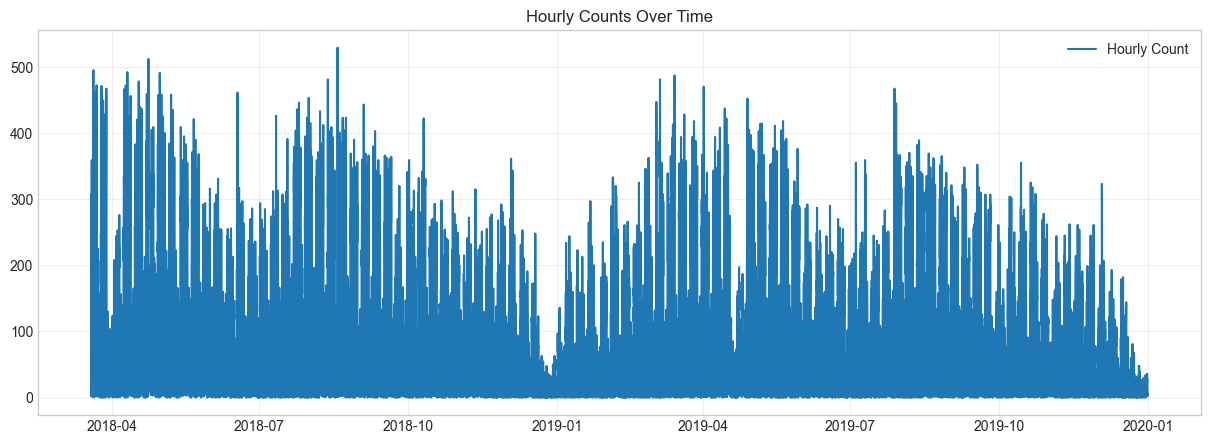

In [6]:
# Plot the dataset
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], label='Hourly Count', color='#1f77b4')
plt.title('Hourly Counts Over Time')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [7]:
# =============================================================================
# ML MODELS - PART 3: PREPARE DATA WITH FEATURES
# =============================================================================

# Use the data with values (same as before)
df_with_values = df[df['value'].notna()].copy()

print(f"Original data: {len(df_with_values)} observations")
print(f"Date range: {df_with_values.index.min()} to {df_with_values.index.max()}")

# Create all features
df_features = create_all_features(df_with_values, target_col='value')

print(f"\nFeatures created:")
print(f"  Shape: {df_features.shape}")
print(f"  Columns: {df_features.columns.tolist()}")

Original data: 15668 observations
Date range: 2018-03-19 04:00:01 to 2019-12-31 23:00:01
Creating features...
  - Time features... ✓
  - Lag features... ✓
  - Rolling features... ✓

Feature engineering complete!
  Total features created: 45
  Rows dropped (due to NaN): 336
  Remaining rows: 15332

Features created:
  Shape: (15332, 46)
  Columns: ['value', 'hour', 'day_of_week', 'day_of_month', 'day_of_year', 'week_of_year', 'month', 'quarter', 'year', 'is_weekend', 'is_month_start', 'is_month_end', 'is_quarter_start', 'is_quarter_end', 'is_business_hours', 'is_night', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'is_holiday', 'days_to_holiday', 'days_from_holiday', 'hour_x_dow', 'hour_x_is_weekend', 'is_weekend_x_is_holiday', 'lag_1', 'lag_2', 'lag_24', 'lag_48', 'lag_168', 'lag_336', 'rolling_mean_24', 'rolling_std_24', 'rolling_min_24', 'rolling_max_24', 'rolling_median_24', 'rolling_mean_168', 'rolling_std_168', 'rolling_min_168', 'r

In [8]:
FORECAST_HORIZON = 1440  # 60 days * 24 hours

# After feature engineering, we need to split
# The last 336 rows (due to lag_336) are already dropped

# Split indices
train_end_idx = len(df_features) - FORECAST_HORIZON
val_end_idx = len(df_features)

train_ml = df_features.iloc[:train_end_idx].copy()
validation_ml = df_features.iloc[train_end_idx:val_end_idx].copy()

print(f"\n{'='*80}")
print(f"ML DATA SPLIT")
print(f"{'='*80}")
print(f"Training set:   {len(train_ml):,} obs | {train_ml.index.min()} to {train_ml.index.max()}")
print(f"Validation set: {len(validation_ml):,} obs | {validation_ml.index.min()} to {validation_ml.index.max()}")
print(f"{'='*80}")

# Separate features and target
feature_cols = [col for col in df_features.columns if col != 'value']

X_train = train_ml[feature_cols]
y_train = train_ml['value']

X_val = validation_ml[feature_cols]
y_val = validation_ml['value']

print(f"\nFeature matrix shapes:")
print(f"  X_train: {X_train.shape}")
print(f"  X_val: {X_val.shape}")
print(f"\nNumber of features: {len(feature_cols)}")


ML DATA SPLIT
Training set:   13,892 obs | 2018-04-02 04:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01

Feature matrix shapes:
  X_train: (13892, 45)
  X_val: (1440, 45)

Number of features: 45



TRAINING LIGHTGBM MODEL

LightGBM Parameters:
  objective: regression
  metric: rmse
  boosting_type: gbdt
  num_leaves: 31
  learning_rate: 0.05
  feature_fraction: 0.8
  bagging_fraction: 0.8
  bagging_freq: 5
  max_depth: 7
  min_child_samples: 20
  reg_alpha: 0.1
  reg_lambda: 0.1
  verbose: -1
  random_state: 42

Training LightGBM...
Training until validation scores don't improve for 50 rounds
[100]	train's rmse: 20.9844	valid's rmse: 17.4778
[200]	train's rmse: 19.0388	valid's rmse: 17.1056
[300]	train's rmse: 17.4972	valid's rmse: 17.1101
Early stopping, best iteration is:
[265]	train's rmse: 18.0412	valid's rmse: 17.022

✓ LightGBM training complete!
  Best iteration: 265
  Best score: 17.0220

METRICS LIGHTGBM VALIDATION
RMSE:  17.02
MAE:   10.35
MAPE:  51152034040215840.00% (all data)
MAPE:  40.53% (excluding zeros)

Top 20 Most Important Features (LightGBM):
           feature   importance
             lag_1 6.340932e+08
           lag_168 2.489607e+08
           lag_336 3.

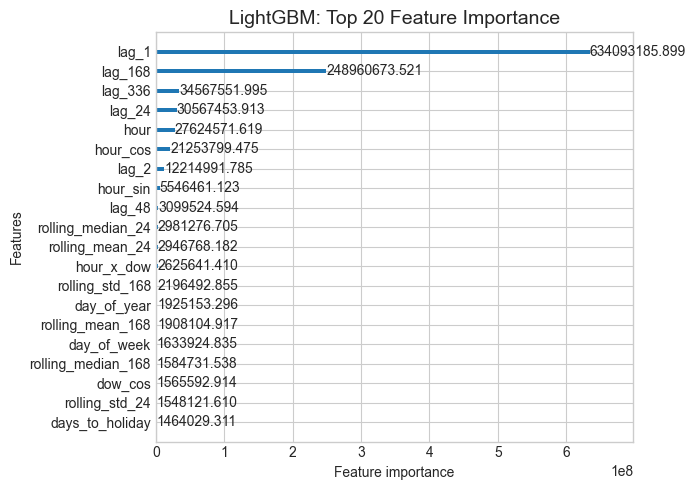

In [ ]:
# =============================================================================
# ML MODELS - PART 4: LIGHTGBM
# =============================================================================

print("\n" + "=" * 80)
print("TRAINING LIGHTGBM MODEL")
print("=" * 80)

# LightGBM parameters (tuned for time series)
lgb_params = {
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'num_leaves': 31,
    'learning_rate': 0.05,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'max_depth': 7,
    'min_child_samples': 20,
    'reg_alpha': 0.1,
    'reg_lambda': 0.1,
    'verbose': -1,
    'random_state': 42
}

print("\nLightGBM Parameters:")
for key, value in lgb_params.items():
    print(f"  {key}: {value}")

# Create datasets
lgb_train = lgb.Dataset(X_train, y_train)
lgb_val = lgb.Dataset(X_val, y_val, reference=lgb_train)

# Train model
print("\nTraining LightGBM...")
lgb_model = lgb.train(
    lgb_params,
    lgb_train,
    num_boost_round=1000,
    valid_sets=[lgb_train, lgb_val],
    valid_names=['train', 'valid'],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

print(f"\n✓ LightGBM training complete!")
print(f"  Best iteration: {lgb_model.best_iteration}")
print(f"  Best score: {lgb_model.best_score['valid']['rmse']:.4f}")

# Make predictions on validation set
lgb_val_pred = lgb_model.predict(X_val, num_iteration=lgb_model.best_iteration)
lgb_val_pred = np.clip(lgb_val_pred, 0, None)  # Clip negative predictions

# Calculate metrics
def calculate_metrics(actual, predicted, name=""):
    """Calculate and print forecast metrics."""
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    
    # Handle MAPE for zero values
    mask = actual > 0
    mape_nonzero = mean_absolute_percentage_error(actual[mask], predicted[mask]) * 100
    
    print(f"\n{'='*50}")
    print(f"METRICS {name}")
    print(f"{'='*50}")
    print(f"RMSE:  {rmse:.2f}")
    print(f"MAE:   {mae:.2f}")
    print(f"MAPE:  {mape:.2f}% (all data)")
    print(f"MAPE:  {mape_nonzero:.2f}% (excluding zeros)")
    print(f"{'='*50}")
    
    return {'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_nonzero': mape_nonzero}

lgb_metrics = calculate_metrics(y_val, lgb_val_pred, name="LIGHTGBM VALIDATION")

# Feature importance
print("\nTop 20 Most Important Features (LightGBM):")
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': lgb_model.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

print(feature_importance.head(20).to_string(index=False))

# Plot feature importance
fig, ax = plt.subplots(figsize=(7, 5))
lgb.plot_importance(lgb_model, max_num_features=20, ax=ax, importance_type='gain')
plt.title('LightGBM: Top 20 Feature Importance', fontsize=14)
plt.tight_layout()
plt.show()


TRAINING XGBOOST MODEL

XGBoost Parameters:
  objective: reg:squarederror
  eval_metric: rmse
  booster: gbtree
  max_depth: 7
  learning_rate: 0.05
  subsample: 0.8
  colsample_bytree: 0.8
  min_child_weight: 3
  gamma: 0.1
  reg_alpha: 0.1
  reg_lambda: 1.0
  random_state: 42
  verbosity: 1

Training XGBoost...
[0]	train-rmse:93.08493	valid-rmse:68.62955
[100]	train-rmse:17.16405	valid-rmse:17.18858
[165]	train-rmse:15.04815	valid-rmse:17.18701

✓ XGBoost training complete!
  Best iteration: 115
  Best score: 17.1699

METRICS XGBOOST VALIDATION
RMSE:  17.17
MAE:   10.44
MAPE:  64847225378133376.00% (all data)
MAPE:  42.88% (excluding zeros)

Top 20 Most Important Features (XGBoost):
           feature    importance
             lag_1 448087.062500
           lag_168 215359.875000
          is_night 112296.210938
            lag_24  40754.507812
              hour  38141.871094
          hour_cos  36967.113281
           lag_336  28242.814453
             lag_2  22090.058594
       d

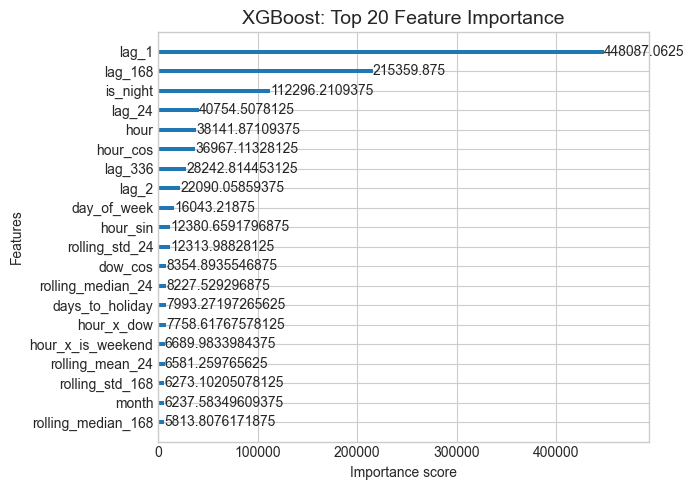

In [11]:
# =============================================================================
# ML MODELS - PART 5: XGBOOST
# =============================================================================

print("\n" + "=" * 80)
print("TRAINING XGBOOST MODEL")
print("=" * 80)

# XGBoost parameters (tuned for time series)
xgb_params = {
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'booster': 'gbtree',
    'max_depth': 7,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 3,
    'gamma': 0.1,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'random_state': 42,
    'verbosity': 1
}

print("\nXGBoost Parameters:")
for key, value in xgb_params.items():
    print(f"  {key}: {value}")

# Create DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)

# Train model
print("\nTraining XGBoost...")
evals = [(dtrain, 'train'), (dval, 'valid')]

xgb_model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=1000,
    evals=evals,
    early_stopping_rounds=50,
    verbose_eval=100
)

print(f"\n✓ XGBoost training complete!")
print(f"  Best iteration: {xgb_model.best_iteration}")
print(f"  Best score: {xgb_model.best_score:.4f}")

# Make predictions on validation set
xgb_val_pred = xgb_model.predict(dval, iteration_range=(0, xgb_model.best_iteration + 1))
xgb_val_pred = np.clip(xgb_val_pred, 0, None)  # Clip negative predictions

# Calculate metrics
xgb_metrics = calculate_metrics(y_val, xgb_val_pred, name="XGBOOST VALIDATION")

# Feature importance
print("\nTop 20 Most Important Features (XGBoost):")
xgb_importance = xgb_model.get_score(importance_type='gain')
xgb_importance_df = pd.DataFrame({
    'feature': list(xgb_importance.keys()),
    'importance': list(xgb_importance.values())
}).sort_values('importance', ascending=False)

print(xgb_importance_df.head(20).to_string(index=False))

# Plot feature importance
fig, ax = plt.subplots(figsize=(7, 5))
xgb.plot_importance(xgb_model, max_num_features=20, ax=ax, importance_type='gain')
plt.title('XGBoost: Top 20 Feature Importance', fontsize=14)
plt.tight_layout()
plt.show()


MODEL COMPARISON - VALIDATION RESULTS

   Model      RMSE       MAE  MAPE_nonzero
LightGBM 17.021692 10.348113     40.526874
 XGBoost 17.169888 10.436152     42.879650
     UCM 56.410000 38.810000    199.700000
  SARIMA 65.400000 51.210000    472.020000

🏆 BEST MODEL (by RMSE): LightGBM
   RMSE: 17.02
   MAE: 10.35


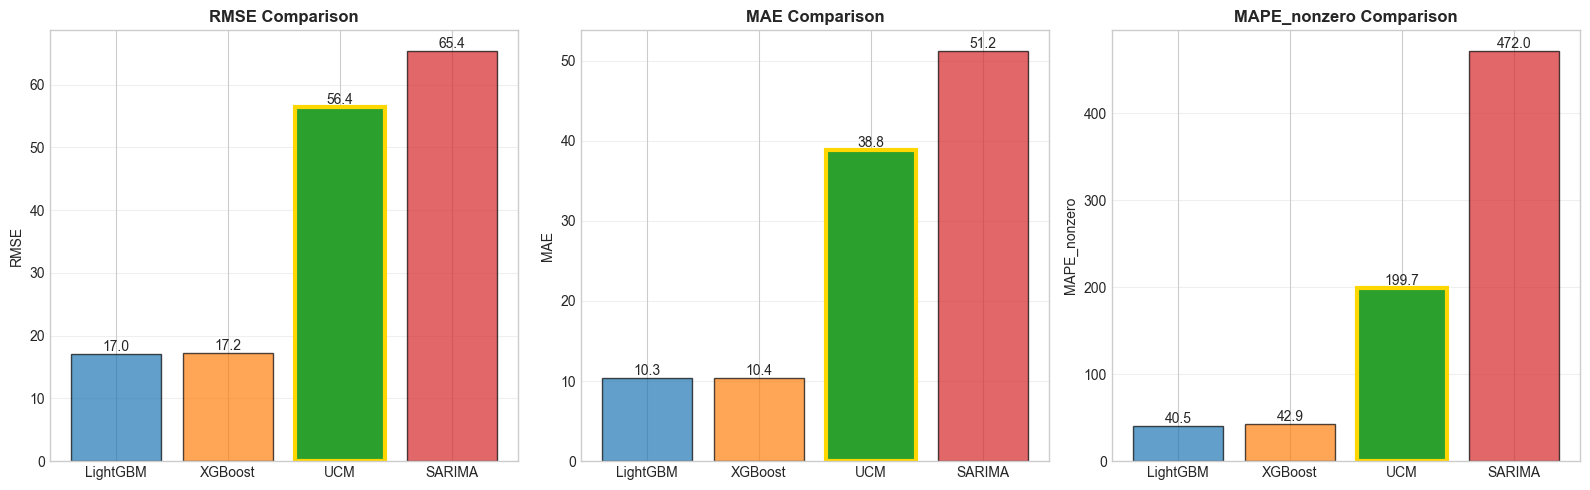

In [ ]:
# =============================================================================
# ML MODELS - PART 6: MODEL COMPARISON (VALIDATION)
# =============================================================================

print("\n" + "=" * 80)
print("MODEL COMPARISON - VALIDATION RESULTS")
print("=" * 80)

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Model': ['SARIMA', 'UCM', 'LightGBM', 'XGBoost'],
    'RMSE': [65.40, 56.41, lgb_metrics['rmse'], xgb_metrics['rmse']],
    'MAE': [51.21, 38.81, lgb_metrics['mae'], xgb_metrics['mae']],
    'MAPE_nonzero': [472.02, 199.70, lgb_metrics['mape_nonzero'], xgb_metrics['mape_nonzero']]
})

# Sort by RMSE
comparison_df = comparison_df.sort_values('RMSE')

print("\n" + comparison_df.to_string(index=False))
print("=" * 80)

# Determine winner
best_model = comparison_df.iloc[0]['Model']
print(f"\n🏆 BEST MODEL (by RMSE): {best_model}")
print(f"   RMSE: {comparison_df.iloc[0]['RMSE']:.2f}")
print(f"   MAE: {comparison_df.iloc[0]['MAE']:.2f}")

# Visualize comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics_to_plot = ['RMSE', 'MAE', 'MAPE_nonzero']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx]
    bars = ax.bar(comparison_df['Model'], comparison_df[metric], color=colors, alpha=0.7, edgecolor='black')
    
    # Highlight best
    best_idx = comparison_df[metric].idxmin()
    bars[best_idx].set_alpha(1.0)
    bars[best_idx].set_edgecolor('gold')
    bars[best_idx].set_linewidth(3)
    
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

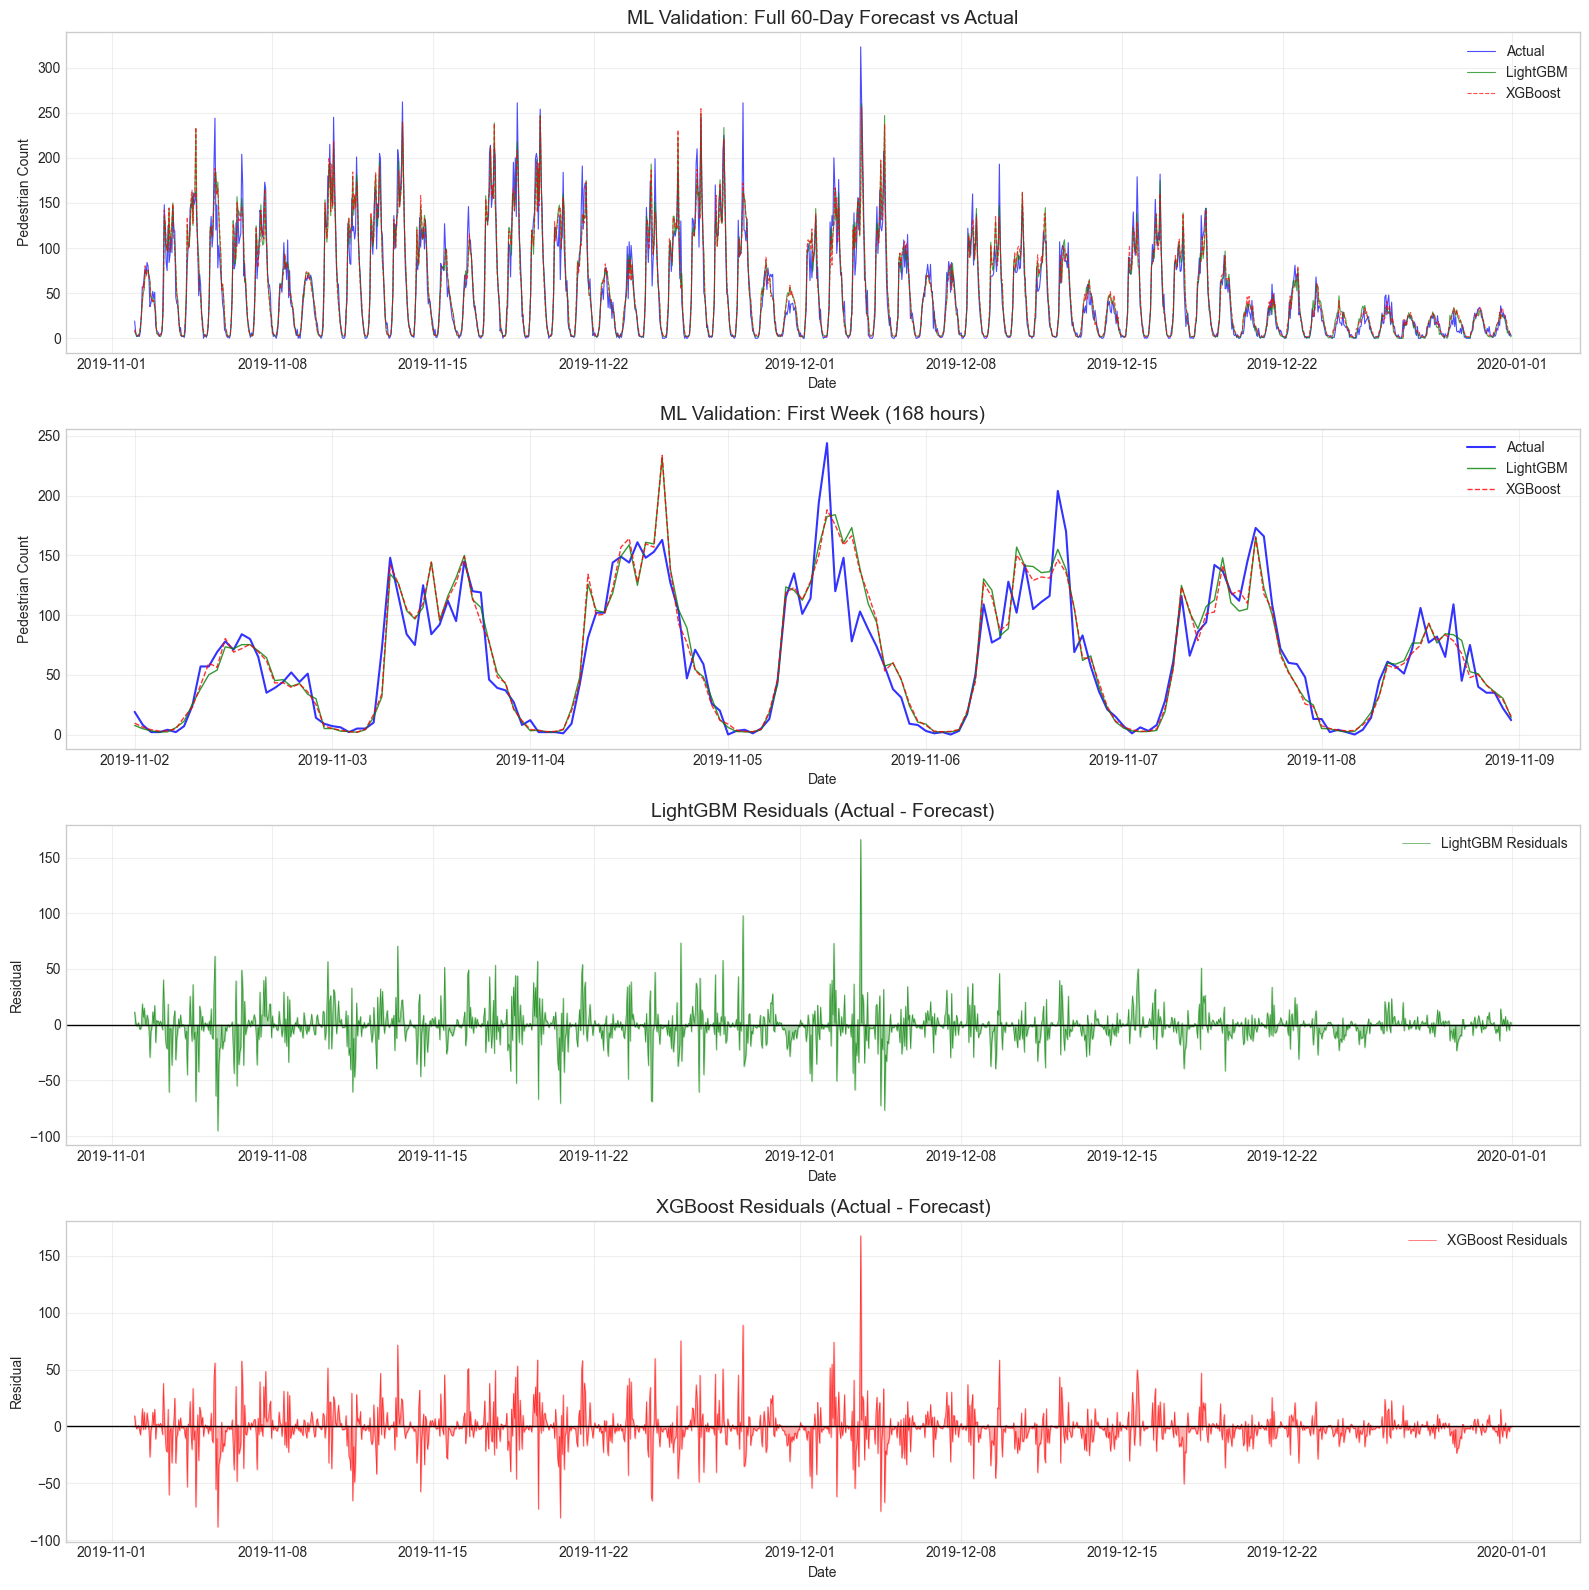

In [13]:
# =============================================================================
# ML MODELS - PART 7: VISUALIZATION OF VALIDATION FORECASTS
# =============================================================================

# Create validation forecast DataFrames
lgb_val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': lgb_val_pred,
    'date': y_val.index
}).set_index('date')

xgb_val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': xgb_val_pred,
    'date': y_val.index
}).set_index('date')

# Plot validation forecasts
fig, axes = plt.subplots(4, 1, figsize=(16, 16))

# Plot 1: Full 60-day validation period
ax1 = axes[0]
ax1.plot(y_val.index, y_val.values, label='Actual', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(lgb_val_forecast_df.index, lgb_val_forecast_df['forecast'], 
         label='LightGBM', alpha=0.7, linewidth=0.8, color='green')
ax1.plot(xgb_val_forecast_df.index, xgb_val_forecast_df['forecast'], 
         label='XGBoost', alpha=0.7, linewidth=0.8, color='red', linestyle='--')
ax1.set_title('ML Validation: Full 60-Day Forecast vs Actual', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: First week zoom
first_week = slice(0, 168)
ax2 = axes[1]
ax2.plot(y_val.index[first_week], y_val.values[first_week], 
         label='Actual', alpha=0.8, linewidth=1.5, color='blue')
ax2.plot(lgb_val_forecast_df.index[first_week], lgb_val_forecast_df['forecast'].values[first_week], 
         label='LightGBM', alpha=0.8, linewidth=1, color='green')
ax2.plot(xgb_val_forecast_df.index[first_week], xgb_val_forecast_df['forecast'].values[first_week], 
         label='XGBoost', alpha=0.8, linewidth=1, color='red', linestyle='--')
ax2.set_title('ML Validation: First Week (168 hours)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: LightGBM Residuals
lgb_residuals = y_val.values - lgb_val_pred
ax3 = axes[2]
ax3.plot(y_val.index, lgb_residuals, alpha=0.7, linewidth=0.5, color='green', label='LightGBM Residuals')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.fill_between(y_val.index, lgb_residuals, 0, alpha=0.3, color='green')
ax3.set_title('LightGBM Residuals (Actual - Forecast)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Residual')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: XGBoost Residuals
xgb_residuals = y_val.values - xgb_val_pred
ax4 = axes[3]
ax4.plot(y_val.index, xgb_residuals, alpha=0.7, linewidth=0.5, color='red', label='XGBoost Residuals')
ax4.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax4.fill_between(y_val.index, xgb_residuals, 0, alpha=0.3, color='red')
ax4.set_title('XGBoost Residuals (Actual - Forecast)', fontsize=14)
ax4.set_xlabel('Date')
ax4.set_ylabel('Residual')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# =============================================================================
# ML MODELS - PART 8: RETRAIN ON FULL DATA & FINAL FORECAST
# =============================================================================

print("\n" + "=" * 80)
print("RETRAINING ML MODELS ON FULL DATA")
print("=" * 80)

# Combine train and validation for final training
full_train_ml = pd.concat([train_ml, validation_ml])

X_full = full_train_ml[feature_cols]
y_full = full_train_ml['value']

print(f"\nFull training data: {len(X_full):,} observations")
print(f"Date range: {X_full.index.min()} to {X_full.index.max()}")

# =============================================================================
# RETRAIN LIGHTGBM
# =============================================================================

print("\n" + "-" * 80)
print("Retraining LightGBM on full data...")
print("-" * 80)

lgb_full_train = lgb.Dataset(X_full, y_full)

lgb_final_model = lgb.train(
    lgb_params,
    lgb_full_train,
    num_boost_round=lgb_model.best_iteration,  # Use best iteration from validation
)

print("✓ LightGBM retrained successfully")

# =============================================================================
# RETRAIN XGBOOST
# =============================================================================

print("\n" + "-" * 80)
print("Retraining XGBoost on full data...")
print("-" * 80)

dfull = xgb.DMatrix(X_full, label=y_full)

xgb_final_model = xgb.train(
    xgb_params,
    dfull,
    num_boost_round=xgb_model.best_iteration,  # Use best iteration from validation
    verbose_eval=False
)

print("✓ XGBoost retrained successfully")



RETRAINING ML MODELS ON FULL DATA

Full training data: 15,332 observations
Date range: 2018-04-02 04:00:01 to 2019-12-31 23:00:01

--------------------------------------------------------------------------------
Retraining LightGBM on full data...
--------------------------------------------------------------------------------
✓ LightGBM retrained successfully

--------------------------------------------------------------------------------
Retraining XGBoost on full data...
--------------------------------------------------------------------------------
✓ XGBoost retrained successfully


In [17]:
# =============================================================================
# PREPARE FORECAST FEATURES
# =============================================================================

print("\n" + "-" * 80)
print("Preparing features for forecast period...")
print("-" * 80)

# Create future dates
last_date = X_full.index.max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=FORECAST_HORIZON,
    freq='H'
)

print(f"Forecast period: {future_dates.min()} to {future_dates.max()}")

# Create a DataFrame with future dates
future_df = pd.DataFrame(index=future_dates)
future_df['value'] = np.nan  # Placeholder for target

# IMPORTANT: For forecasting, we need to iteratively predict
# because lag features depend on previous predictions

print("\nGenerating iterative forecasts (this may take a moment)...")

# Initialize with the last known values from training
historical_values = full_train_ml['value'].copy()

# Storage for predictions
lgb_forecast_list = []
xgb_forecast_list = []

for i, future_date in enumerate(future_dates):
    if (i + 1) % 240 == 0:  # Progress update every 10 days
        print(f"  Forecasting hour {i+1}/{FORECAST_HORIZON}...")
    
    # Create temporary df with historical + current future point
    temp_df = pd.DataFrame({'value': historical_values})
    temp_df = pd.concat([temp_df, pd.DataFrame({'value': [np.nan]}, index=[future_date])])
    
    # Create features for this single point
    temp_with_features = create_time_features(temp_df, target_col='value')
    temp_with_features = create_lag_features(temp_with_features, target_col='value', lags=[1, 2, 24, 48, 168, 336])
    temp_with_features = create_rolling_features(temp_with_features, target_col='value', windows=[24, 168])
    
    # Get the last row (our forecast point)
    forecast_features = temp_with_features.iloc[-1:][feature_cols]
    
    # Check if we have all features (no NaN)
    if forecast_features.isna().any().any():
        # If we have NaN, use the mean of recent predictions or last known value
        # This shouldn't happen if lags are properly set, but safety check
        lgb_pred = historical_values.iloc[-24:].mean()
        xgb_pred = historical_values.iloc[-24:].mean()
    else:
        # Make predictions
        lgb_pred = lgb_final_model.predict(forecast_features)[0]
        lgb_pred = max(0, lgb_pred)  # Clip to non-negative
        
        dforecast = xgb.DMatrix(forecast_features)
        xgb_pred = xgb_final_model.predict(dforecast)[0]
        xgb_pred = max(0, xgb_pred)  # Clip to non-negative
    
    # Store predictions
    lgb_forecast_list.append(lgb_pred)
    xgb_forecast_list.append(xgb_pred)
    
    # Update historical values with the average of both predictions for next iteration
    # (or you could use just one model - using average for robustness)
    avg_pred = (lgb_pred + xgb_pred) / 2
    historical_values = pd.concat([historical_values, pd.Series([avg_pred], index=[future_date])])

print("✓ Forecasts generated")

# Create forecast DataFrames
lgb_final_forecast_df = pd.DataFrame({
    'date': future_dates,
    'forecast': lgb_forecast_list
}).set_index('date')

xgb_final_forecast_df = pd.DataFrame({
    'date': future_dates,
    'forecast': xgb_forecast_list
}).set_index('date')

print("\nForecast Summary (LightGBM):")
print(lgb_final_forecast_df.describe())

print("\nForecast Summary (XGBoost):")
print(xgb_final_forecast_df.describe())


--------------------------------------------------------------------------------
Preparing features for forecast period...
--------------------------------------------------------------------------------
Forecast period: 2020-01-01 00:00:01 to 2020-02-29 23:00:01

Generating iterative forecasts (this may take a moment)...
  Forecasting hour 240/1440...
  Forecasting hour 480/1440...
  Forecasting hour 720/1440...
  Forecasting hour 960/1440...
  Forecasting hour 1200/1440...
  Forecasting hour 1440/1440...
✓ Forecasts generated

Forecast Summary (LightGBM):
          forecast
count  1440.000000
mean     37.393825
std      31.982399
min       1.461872
25%       5.055479
50%      32.630497
75%      62.979535
max     136.995139

Forecast Summary (XGBoost):
          forecast
count  1440.000000
mean     36.978958
std      30.582014
min       1.897028
25%       4.857888
50%      32.820501
75%      62.911346
max     121.505020


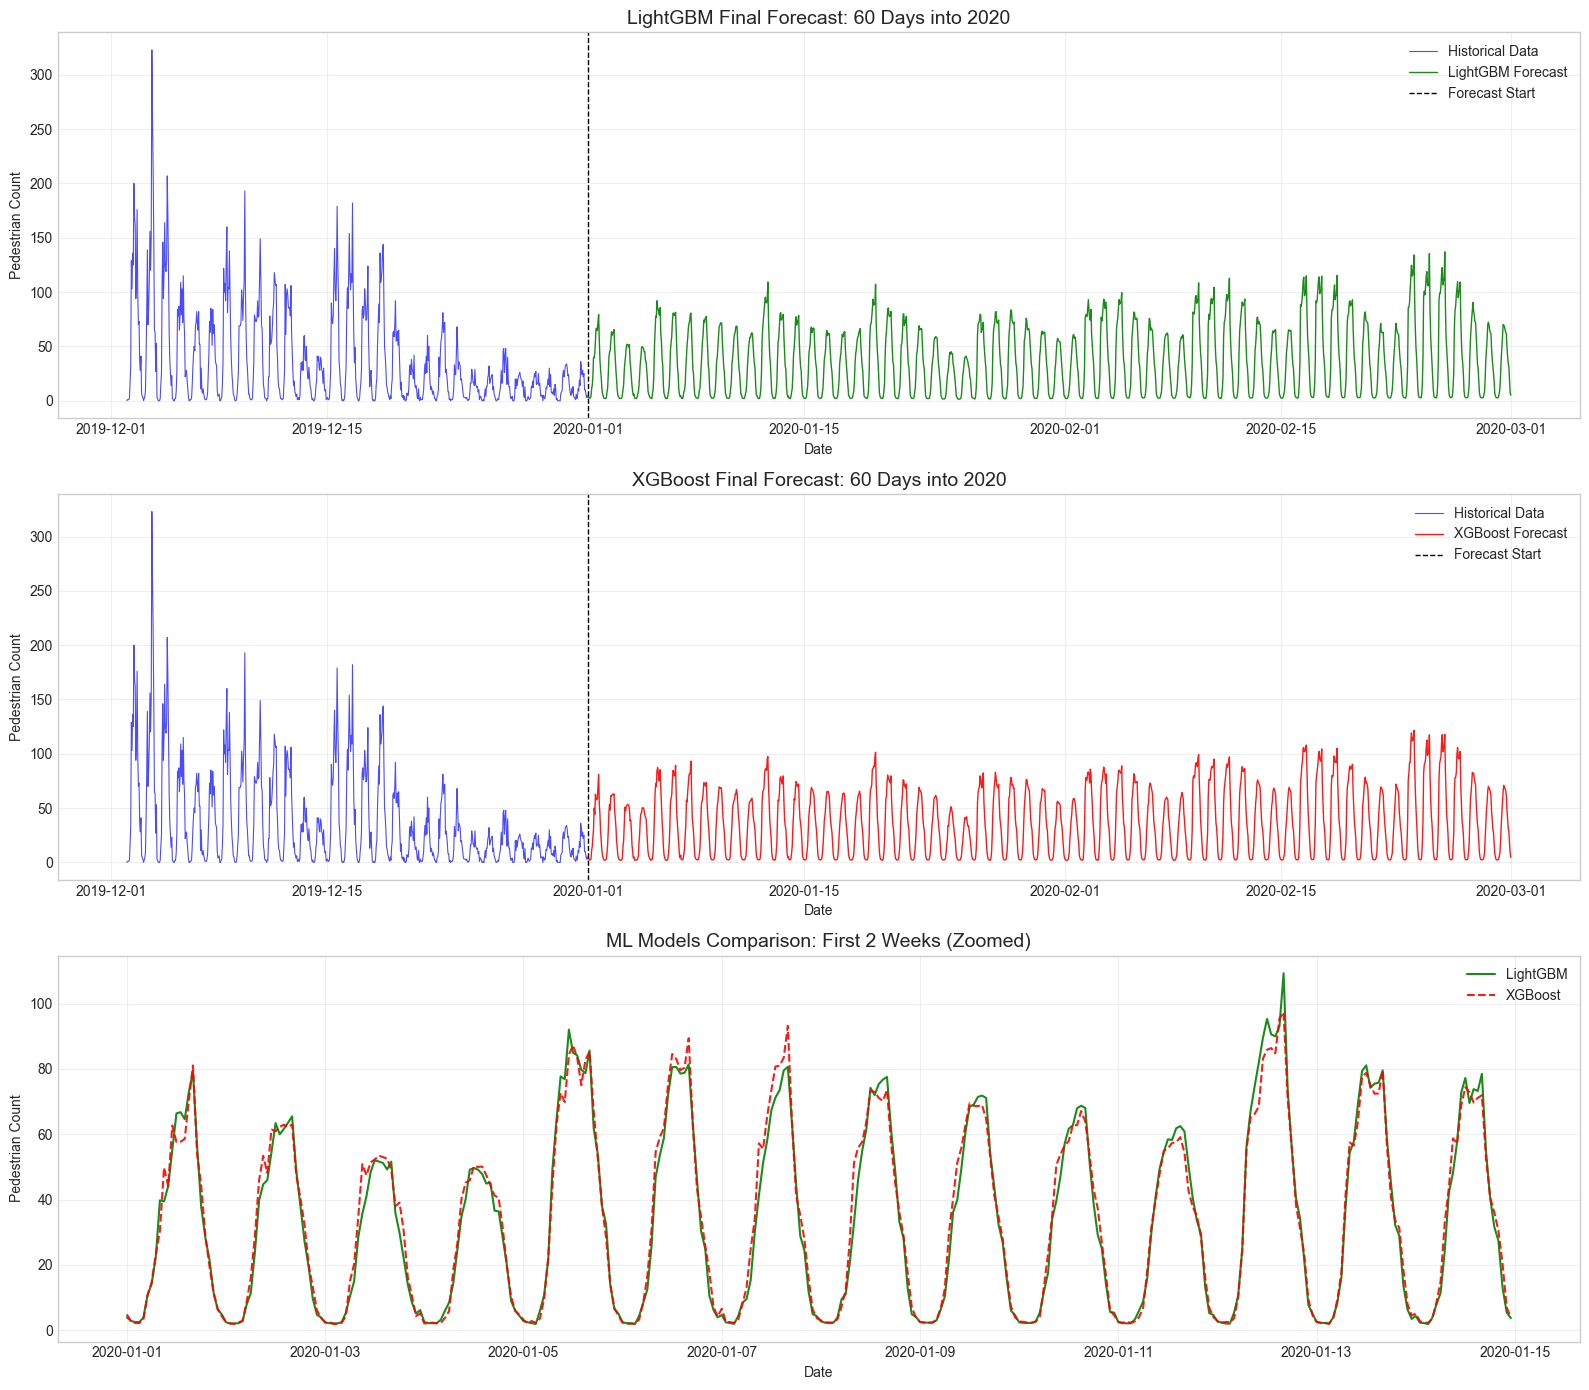

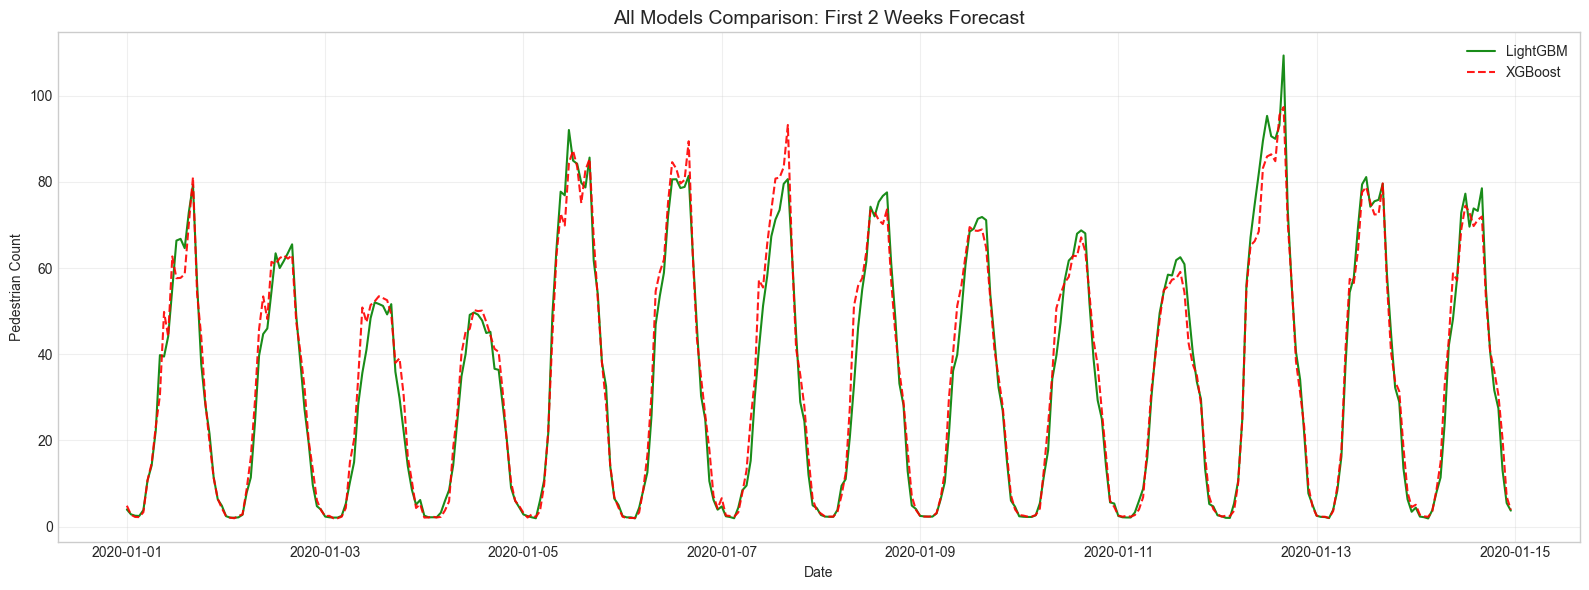

In [ ]:
# =============================================================================
# ML MODELS - PART 9: VISUALIZE FINAL FORECASTS
# =============================================================================

fig, axes = plt.subplots(3, 1, figsize=(16, 14))

# Last 30 days of training data for context
context_data = y_full.iloc[-720:]

# Plot 1: LightGBM Final Forecast
ax1 = axes[0]
ax1.plot(context_data.index, context_data.values, 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(lgb_final_forecast_df.index, lgb_final_forecast_df['forecast'], 
         label='LightGBM Forecast', alpha=0.9, linewidth=1, color='green')
ax1.axvline(x=y_full.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax1.set_title('LightGBM Final Forecast: 60 Days into 2020', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Plot 2: XGBoost Final Forecast
ax2 = axes[1]
ax2.plot(context_data.index, context_data.values, 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax2.plot(xgb_final_forecast_df.index, xgb_final_forecast_df['forecast'], 
         label='XGBoost Forecast', alpha=0.9, linewidth=1, color='red')
ax2.axvline(x=y_full.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax2.set_title('XGBoost Final Forecast: 60 Days into 2020', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

# Plot 3: Both ML Models Comparison (First 2 weeks)
first_two_weeks = slice(0, 336)
ax3 = axes[2]
ax3.plot(lgb_final_forecast_df.index[first_two_weeks], 
         lgb_final_forecast_df['forecast'].values[first_two_weeks], 
         label='LightGBM', alpha=0.9, linewidth=1.5, color='green')
ax3.plot(xgb_final_forecast_df.index[first_two_weeks], 
         xgb_final_forecast_df['forecast'].values[first_two_weeks], 
         label='XGBoost', alpha=0.9, linewidth=1.5, color='red', linestyle='--')
ax3.set_title('ML Models Comparison: First 2 Weeks (Zoomed)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Pedestrian Count')
ax3.legend(loc='upper right')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Additional plot: All 4 models together (first 2 weeks)
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(lgb_final_forecast_df.index[first_two_weeks], 
        lgb_final_forecast_df['forecast'].values[first_two_weeks], 
        label='LightGBM', alpha=0.9, linewidth=1.5, color='green')
ax.plot(xgb_final_forecast_df.index[first_two_weeks], 
        xgb_final_forecast_df['forecast'].values[first_two_weeks], 
        label='XGBoost', alpha=0.9, linewidth=1.5, color='red', linestyle='--')

ax.set_title('All Models Comparison: First 2 Weeks Forecast', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Pedestrian Count')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()